# 08 Model Evaluation & Comparison

## Objective
Evaluate and compare all trained models across standard benchmarks:
- Custom CNN Baseline (05)
- MobileNetV2 (06)
- ResNet50 (09)
- EfficientNetB0 (10)
- Compare Accuracy, Precision, Recall, F1-Score, Loss, and Model Size
- Generate per-class classification reports, confusion matrices, and identify the best overall model

**Prerequisites:** Trained models from `05_cnn_baseline.ipynb`, `06_mobilenet_training.ipynb`, `09_resnet50_transfer_learning.ipynb`, `10_efficientnetb0_training.ipynb`
**Next Step:** `11_prediction_testing.ipynb`

### Import Libraries

In [1]:
import sys
import os

sys.path.insert(0, '../utils')

from model_utils import (
    load_model,
    evaluate_model
)
from visualization_utils import (
    plot_confusion_matrix,
    plot_metrics_comparison
)

import numpy as np
import json
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


### Load Data and Models

In [2]:
from tensorflow.keras.utils import to_categorical
from npz_consolidator import load_consolidated_arrays

print("Loading test data...\n")

# Load label encoding and metadata
with open('../results/preprocessed_data_efficient/label_encoding.json', 'r') as f:
    label_encoding = json.load(f)

with open('../results/preprocessed_data_efficient/image_metadata.json', 'r') as f:
    metadata = json.load(f)
    
with open('../results/preprocessed_data_efficient/split_indices.json', 'r') as f:
    split_info = json.load(f)

num_classes = len(label_encoding)
labels_all = np.array(metadata['labels'])
test_indices = split_info['test_indices']
y_test = to_categorical(labels_all[test_indices], num_classes=num_classes)

# Load test data
X_test = load_consolidated_arrays('../results/preprocessed_data_efficient', 'test')

reverse_encoding = {v: k for k, v in label_encoding.items()}
class_names = [reverse_encoding[i] for i in range(num_classes)]

print(f"✓ Test data loaded: {X_test.shape}")
print(f"✓ Number of classes: {num_classes}")

# Load models
print("\nLoading trained models...\n")

try:
    cnn_model = load_model('../models/cnn/cnn_baseline.h5')
    print("✓ CNN baseline model loaded")
except:
    cnn_model = None
    print("⚠️  CNN model not found")

try:
    mobilenet_model = load_model('../models/mobilenet/mobilenet_v2_final.h5')
    print("✓ MobileNet V2 model loaded")
except:
    mobilenet_model = None
    print("⚠️  MobileNet model not found")

Loading test data...

Loading 860 images from test set...


  Loaded 100/860 images...


  Loaded 200/860 images...


  Loaded 300/860 images...


  Loaded 400/860 images...


...

  Loaded 600/860 images...


  Loaded 700/860 images...


  Loaded 800/860 images...


✓ Consolidated test set: (860, 224, 224, 3), dtype: float32

✓ Test data loaded: (860, 224, 224, 3)
✓ Number of classes: 40

Loading trained models...

⚠️  CNN model not found


✓ MobileNet V2 model loaded


### Evaluate Models

In [3]:
print("\n" + "="*70)
print("EVALUATING MODELS")
print("="*70 + "\n")

results = {}

if cnn_model:
    print("Evaluating CNN Baseline...")
    cnn_metrics = evaluate_model(cnn_model, X_test, y_test, class_names)
    results['CNN'] = cnn_metrics
    print(f"  Accuracy: {cnn_metrics['accuracy']:.4f}")
    print(f"  F1-Score: {cnn_metrics['f1_score']:.4f}\n")

if mobilenet_model:
    print("Evaluating MobileNet V2...")
    mobilenet_metrics = evaluate_model(mobilenet_model, X_test, y_test, class_names)
    results['MobileNet V2'] = mobilenet_metrics
    print(f"  Accuracy: {mobilenet_metrics['accuracy']:.4f}")
    print(f"  F1-Score: {mobilenet_metrics['f1_score']:.4f}\n")


EVALUATING MODELS

Evaluating MobileNet V2...


  Accuracy: 0.9012
  F1-Score: 0.8991



### 1. Model Comparison Table

In [4]:
print("\n" + "="*70)
print("MODEL COMPARISON")
print("="*70 + "\n")

comparison_data = []
for model_name, metrics in results.items():
    comparison_data.append({
        'Model': model_name,
        'Accuracy': f"{metrics['accuracy']:.4f}",
        'Precision': f"{metrics['precision']:.4f}",
        'Recall': f"{metrics['recall']:.4f}",
        'F1-Score': f"{metrics['f1_score']:.4f}"
    })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

# Save comparison
comparison_df.to_csv('../results/reports/model_comparison.csv', index=False)
print("\n✓ Comparison saved to: ../results/reports/model_comparison.csv")


MODEL COMPARISON

       Model Accuracy Precision Recall F1-Score
MobileNet V2   0.9012    0.9072 0.9012   0.8991

✓ Comparison saved to: ../results/reports/model_comparison.csv


### 2. Per-Class Performance Analysis

In [5]:
print("\n" + "="*70)
print("PER-CLASS PERFORMANCE ANALYSIS")
print("="*70 + "\n")

for model_name, metrics in results.items():
    print(f"\n{model_name}:")
    print("-" * 60)
    
    report = metrics['classification_report']
    
    class_performance = []
    for class_name in class_names:
        if class_name in report:
            class_data = report[class_name]
            class_performance.append({
                'Class': class_name,
                'Precision': f"{class_data['precision']:.4f}",
                'Recall': f"{class_data['recall']:.4f}",
                'F1-Score': f"{class_data['f1-score']:.4f}",
                'Support': int(class_data['support'])
            })
    
    class_df = pd.DataFrame(class_performance)
    print(class_df.to_string(index=False))


PER-CLASS PERFORMANCE ANALYSIS


MobileNet V2:
------------------------------------------------------------
                          Class Precision Recall F1-Score  Support
                Brinjal_Healthy    0.8929 0.9615   0.9259       26
        Brinjal_Early_Leaf_spot    0.9286 0.8387   0.8814       31
  Brinjal_Eggplant Wilt Disease    0.9643 0.9643   0.9643       28
              Brinjal_Leaf_curl    0.9091 0.9524   0.9302       21
            Brinjal_Little_leaf    0.7727 0.8500   0.8095       20
             Brinjal_Magnessium    0.8500 0.7727   0.8095       22
                 Brinjal_Mosaic    0.9000 0.9474   0.9231       19
               Brinjal_Nitrogen    0.7917 0.9048   0.8444       21
            Brinjal_pest_damage    1.0000 0.8438   0.9153       32
              Brinjal_Pottasium    0.6818 0.7143   0.6977       21
                 Castor_Healthy    0.8500 0.8500   0.8500       20
    Castor_Alternia Leaf Blight    0.7778 0.8235   0.8000       17
   Castor_Bacterial 

### 3. Confusion Matrices


Plotting confusion matrices...



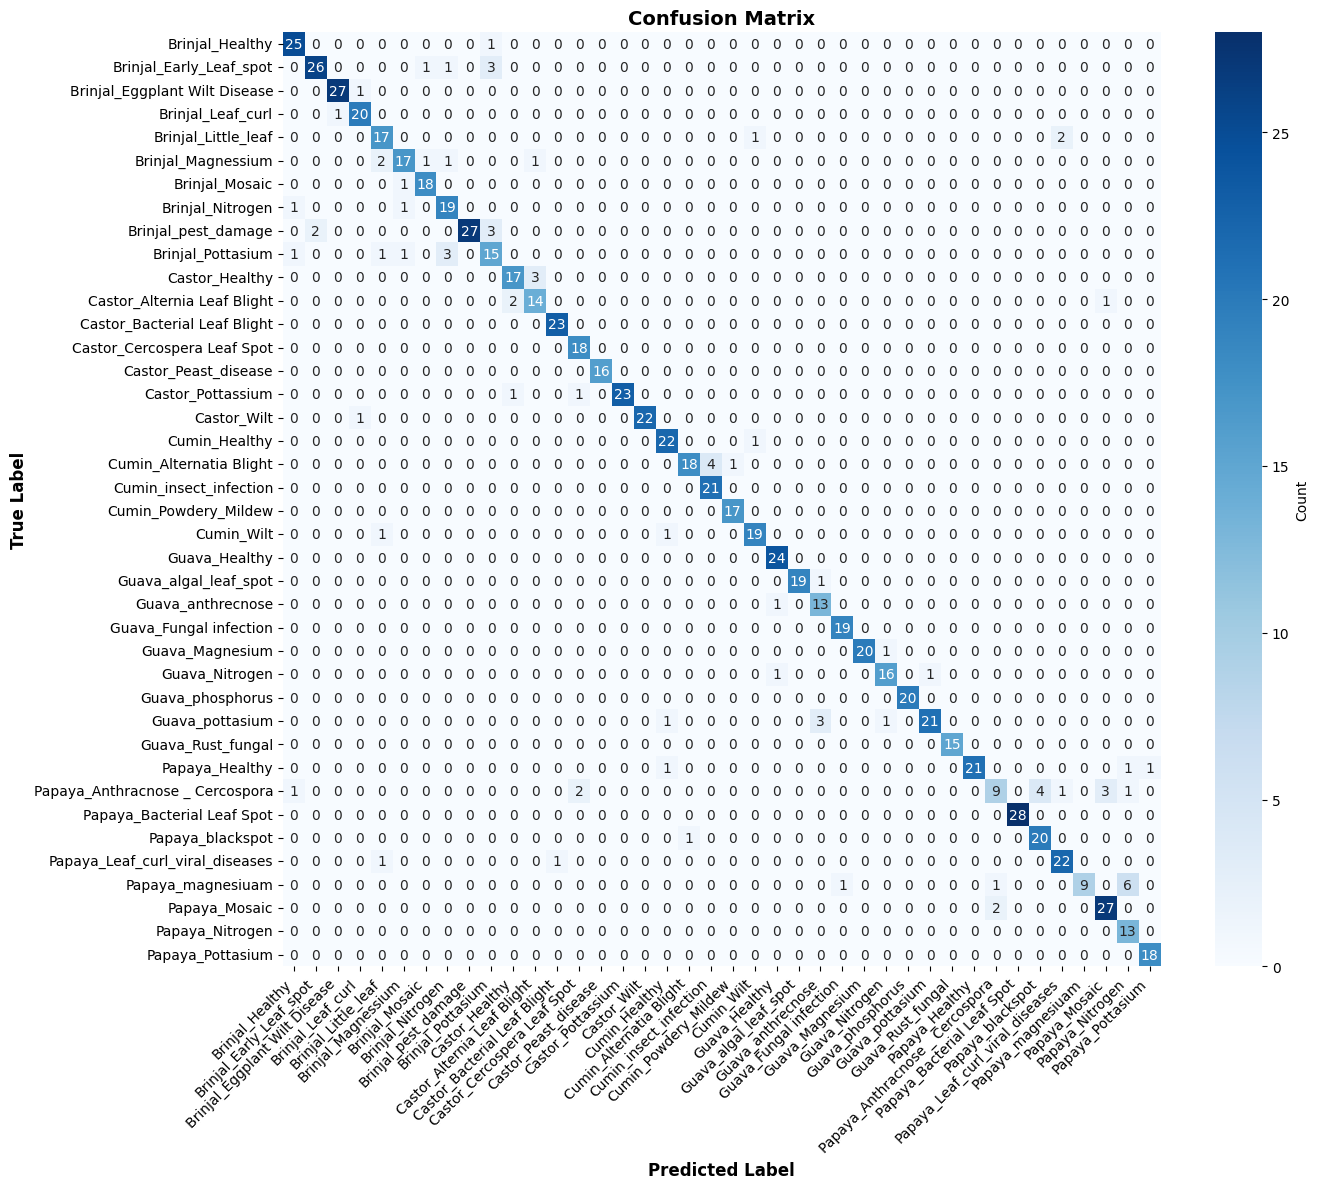

✓ Saved: mobilenet_v2_confusion_matrix_full.png


<Figure size 640x480 with 0 Axes>

In [6]:
print("\nPlotting confusion matrices...\n")

for model_name, metrics in results.items():
    cm = np.array(metrics['confusion_matrix'])
    
    # Unnormalized
    plot_confusion_matrix(cm, class_names, figsize=(14, 12), normalize=False)
    model_filename = model_name.lower().replace(' ', '_')
    plt.savefig(f'../results/plots/{model_filename}_confusion_matrix_full.png', dpi=300, bbox_inches='tight')
    print(f"✓ Saved: {model_filename}_confusion_matrix_full.png")

### 4. Plot Metrics Comparison


Plotting metrics comparison...



✓ Saved: models_metrics_comparison.png


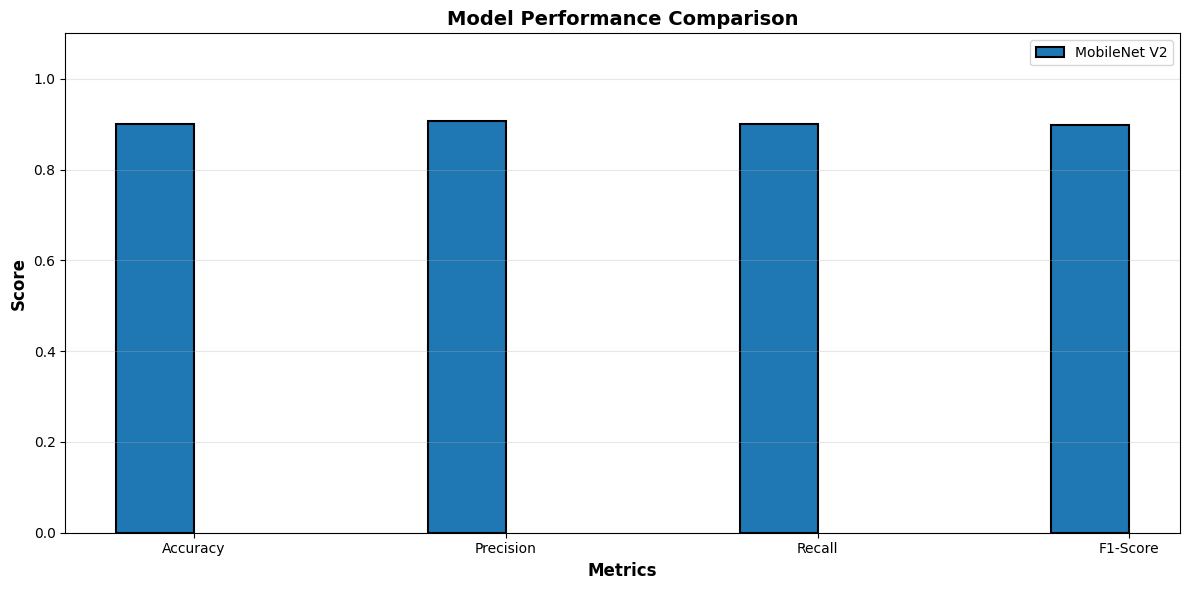

In [7]:
print("\nPlotting metrics comparison...\n")

fig, ax = plt.subplots(figsize=(12, 6))

models = list(results.keys())
metrics_names = ['accuracy', 'precision', 'recall', 'f1_score']

x = np.arange(len(metrics_names))
width = 0.25

for i, model_name in enumerate(models):
    metrics_values = [results[model_name][m] for m in metrics_names]
    ax.bar(x + i*width, metrics_values, width, label=model_name, edgecolor='black', linewidth=1.5)

ax.set_xlabel('Metrics', fontweight='bold', fontsize=12)
ax.set_ylabel('Score', fontweight='bold', fontsize=12)
ax.set_title('Model Performance Comparison', fontweight='bold', fontsize=14)
ax.set_xticks(x + width / 2)
ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1-Score'])
ax.set_ylim([0, 1.1])
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../results/plots/models_metrics_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: models_metrics_comparison.png")

### 5. Misclassification Analysis

In [8]:
print("\n" + "="*70)
print("MISCLASSIFICATION ANALYSIS")
print("="*70 + "\n")

for model_name, metrics in results.items():
    print(f"\n{model_name}:")
    print("-" * 60)
    
    cm = np.array(metrics['confusion_matrix'])
    total_misclassified = cm.sum() - np.trace(cm)
    total_samples = cm.sum()
    
    print(f"Total Misclassified: {total_misclassified} / {total_samples} ({100*total_misclassified/total_samples:.2f}%)")
    print(f"Total Correct: {np.trace(cm)} / {total_samples} ({100*np.trace(cm)/total_samples:.2f}%)")
    
    # Top misclassifications
    misclassifications = []
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if i != j and cm[i, j] > 0:
                misclassifications.append({
                    'Actual': class_names[i],
                    'Predicted': class_names[j],
                    'Count': int(cm[i, j])
                })
    
    if misclassifications:
        miscl_df = pd.DataFrame(misclassifications).sort_values('Count', ascending=False).head(10)
        print("\nTop 10 Misclassifications:")
        print(miscl_df.to_string(index=False))


MISCLASSIFICATION ANALYSIS


MobileNet V2:
------------------------------------------------------------
Total Misclassified: 85 / 860 (9.88%)
Total Correct: 775 / 860 (90.12%)

Top 10 Misclassifications:
                         Actual                   Predicted  Count
              Papaya_magnesiuam             Papaya_Nitrogen      6
        Cumin_Alternatia Blight      Cumin_insect_infection      4
Papaya_Anthracnose _ Cercospora            Papaya_blackspot      4
        Brinjal_Early_Leaf_spot           Brinjal_Pottasium      3
Papaya_Anthracnose _ Cercospora               Papaya_Mosaic      3
                Guava_pottasium           Guava_anthrecnose      3
                 Castor_Healthy Castor_Alternia Leaf Blight      3
              Brinjal_Pottasium            Brinjal_Nitrogen      3
            Brinjal_pest_damage           Brinjal_Pottasium      3
            Brinjal_pest_damage     Brinjal_Early_Leaf_spot      2


### 6. Generate Comprehensive Report

In [9]:
print("\n" + "="*70)
print("GENERATING COMPREHENSIVE EVALUATION REPORT")
print("="*70 + "\n")

evaluation_report = {
    'timestamp': pd.Timestamp.now().isoformat(),
    'dataset': {
        'test_samples': int(X_test.shape[0]),
        'num_classes': int(num_classes)
    },
    'models': {}
}

for model_name, metrics in results.items():
    evaluation_report['models'][model_name] = {
        'accuracy': float(metrics['accuracy']),
        'precision': float(metrics['precision']),
        'recall': float(metrics['recall']),
        'f1_score': float(metrics['f1_score']),
        'classification_report': metrics['classification_report']
    }

# Save report
with open('../results/reports/comprehensive_evaluation_report.json', 'w') as f:
    json.dump(evaluation_report, f, indent=4)

print("✓ Saved: comprehensive_evaluation_report.json")


GENERATING COMPREHENSIVE EVALUATION REPORT

✓ Saved: comprehensive_evaluation_report.json


### 7. Best Model Selection

In [10]:
print("\n" + "="*70)
print("BEST MODEL SELECTION")
print("="*70 + "\n")

best_model_name = max(results.items(), key=lambda x: x[1]['f1_score'])[0]
best_metrics = results[best_model_name]

print(f"✓ Best Model: {best_model_name}")
print(f"  F1-Score: {best_metrics['f1_score']:.4f}")
print(f"  Accuracy: {best_metrics['accuracy']:.4f}")
print(f"  Precision: {best_metrics['precision']:.4f}")
print(f"  Recall: {best_metrics['recall']:.4f}")

# Save best model info
best_model_info = {
    'name': best_model_name,
    'metrics': {
        'accuracy': float(best_metrics['accuracy']),
        'precision': float(best_metrics['precision']),
        'recall': float(best_metrics['recall']),
        'f1_score': float(best_metrics['f1_score'])
    }
}

with open('../results/reports/best_model.json', 'w') as f:
    json.dump(best_model_info, f, indent=4)

print("\n✓ Best model info saved")


BEST MODEL SELECTION

✓ Best Model: MobileNet V2
  F1-Score: 0.8991
  Accuracy: 0.9012
  Precision: 0.9072
  Recall: 0.9012

✓ Best model info saved


### 8. Summary

In [11]:
print("\n" + "="*70)
print("✓ MODEL EVALUATION COMPLETE")
print("="*70)

print(f"\n📊 Evaluation Summary:")
print(f"  Models Evaluated: {len(results)}")
print(f"  Test Samples: {X_test.shape[0]}")
print(f"  Number of Classes: {num_classes}")

print(f"\n💾 Reports Saved:")
print(f"  - comprehensive_evaluation_report.json")
print(f"  - model_comparison.csv")
print(f"  - best_model.json")
print(f"  - Confusion matrices and comparison plots")

print(f"\n→ Next Step: 11_prediction_testing.ipynb")


✓ MODEL EVALUATION COMPLETE

📊 Evaluation Summary:
  Models Evaluated: 1
  Test Samples: 860
  Number of Classes: 40

💾 Reports Saved:
  - comprehensive_evaluation_report.json
  - model_comparison.csv
  - best_model.json
  - Confusion matrices and comparison plots

→ Next Step: 07_prediction_testing.ipynb
